# 05. CNN + Bi-LSTM pada 78 Subjek Sleep Cassette

**Pertanyaan.** Model *deep learning* yang dikembangkan pada 20 subjek muda (notebook 04) unggul tipis atas *baseline*. Apakah keunggulan itu tetap ada ketika model diuji pada seluruh 78 subjek Sleep Cassette, yang berusia 25 sampai 101 tahun?

**Mengapa penting.** Tidur berubah seiring usia: orang tua punya lebih banyak tidur ringan (N1), lebih sedikit tidur dalam (N3), dan sinyalnya lebih banyak gangguan. Model yang hanya diuji pada orang muda belum tentu berguna untuk populasi umum.

**Data.** Seluruh Sleep Cassette: 153 rekaman semalam dari 78 orang sehat. Rekaman sudah dibersihkan dan dinormalkan di notebook 02. Setiap rekaman dipotong menjadi *epoch* 30 detik, dan setiap *epoch* diberi satu dari lima tahap tidur oleh pakar.

**Hasil utama.**
- Pada seluruh data, model CNN + Bi-LSTM lebih baik daripada *baseline*: Macro-F1 78,0 vs 76,5 dan Cohen's κ 0,774 vs 0,739.
- Per orang, model lebih baik pada 48 dari 78 subjek. Namun pada tiga subjek model gagal jauh lebih parah daripada *baseline* (turun 15–25 poin), sehingga rerata keunggulannya per subjek (+1,1 poin) belum terbukti berbeda dari nol.

Istilah seperti *epoch*, *fold*, *seed*, Macro-F1, κ, dan uji statistik yang dipakai dijelaskan di tabel istilah notebook 01.

**Peta notebook**

| Bagian | Isi |
|---|---|
| A–D | Pengaturan, data, pembagian *fold*, dan pemeriksaan model |
| E | Pelatihan: 3 *seed* × 10 *fold* |
| F | Hasil keseluruhan |
| G | Analisis: per subjek, jenis kesalahan, usia, EMG bermasalah, efek data latih, kurva latih |
| H | Penyimpanan, kesimpulan, dan catatan teknis |

## A. Pengaturan

**Tujuan.** Menyalin pengaturan model dan pelatihan dari notebook 04 tanpa mengubah apa pun. Kalau pengaturan disetel ulang setelah melihat hasil pada 20 subjek pertama, padahal 20 subjek itu juga ikut diuji di sini, angka akhirnya akan tampak lebih baik daripada kenyataannya.

**Input.** Pengaturan dari notebook 04: jendela 20 *epoch*, *cross-entropy* tanpa bobot kelas, maksimum 30 putaran latih dengan penghentian dini berdasarkan MF1 validasi.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import confusion_matrix, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "edfx_eda.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
import sleep_dl as sd          # shared code of notebooks 04-06; tests/test_sleep_dl.py proves it equals notebook 04

CACHE = ROOT / "data" / "processed" / "sc"
MANIFEST = ROOT / "results" / "tables" / "02_cache_manifest.csv"
BASELINE_METRICS = ROOT / "results" / "tables" / "03_baseline_metrics.csv"
BASELINE_PRED = ROOT / "data" / "processed" / "baseline_predictions.npz"   # notebook 03
SC20_RUNS = ROOT / "data" / "processed" / "cnn_sc20_runs"                  # notebook 04, compared in G5
RUNS_DIR = ROOT / "data" / "processed" / "cnn_sc78_runs"                   # one file per seed; ignored by git
PREDICTIONS = ROOT / "data" / "processed" / "cnn_sc78_predictions.npz"
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"

SEED = 0                        # same as notebooks 03 and 04: identical folds and validation subjects
STAGES = sd.STAGES
EXPECTED = [65_941, 21_522, 69_132, 13_039, 25_835]     # labelled SC-78 epochs per stage (notebook 02)
AGE_BINS, AGE_LABELS = [24, 39, 59, 79, 120], ["25-39", "40-59", "60-79", "80+"]

# Frozen configuration (decision K6): identical to notebook 04, chosen there on validation data.
# Nothing in this notebook is tuned on SC-78.
CONFIG = dict(seq_len=20, train_stride=10, batch_size=32, lr=1e-3, weight_decay=1e-4,
              max_epochs=30, patience=6, grad_clip=1.0, focal_gamma=2.0, dropout=0.3, val_fraction=0.1,
              loss="ce")                                 # cross-entropy WITHOUT class weights
SEEDS = [0, 1, 2]
N_FOLDS = 10

STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AGE_COLORS = dict(zip(AGE_LABELS, ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]))
MUTED, INK, INK_2, SURFACE, GRID = "#898781", "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
assert BASELINE_PRED.is_file(), "run notebook 03 first"
assert all((SC20_RUNS / f"ce_seed{s}.npz").is_file() for s in SEEDS), "run notebook 04 first"
print("repo root:", ROOT)
print("device   :", sd.DEVICE, f"({torch.cuda.get_device_name(0)})" if sd.USE_AMP else "(no GPU: training will be very slow)")

repo root: D:\sleep-edfx
device   : cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


**Output.** Pengaturan tercetak dan GPU terdeteksi (RTX 3050, 6 GB).

**Kesimpulan.** Tidak ada pengaturan yang dipilih di notebook ini. Kode model dan pelatihan diambil dari modul bersama, yang sudah diuji menghasilkan angka identik dengan notebook 04.

## B. Data

**Tujuan.** Memuat 153 rekaman dan melihat bagaimana komposisi tahap tidur berubah menurut usia.

**Input.** 153 rekaman hasil notebook 02. Sinyal (3,5 GB) dibaca langsung dari disk saat dibutuhkan agar pemakaian RAM tetap rendah.

In [2]:
records = sd.load_records(CACHE, MANIFEST)            # EEG/EOG are memory-mapped: read from disk when needed
labels_all = np.concatenate([r["labels"] for r in records])
subject_all = np.concatenate([[r["subject"]] * len(r["labels"]) for r in records])
rec_all = np.concatenate([[r["rec"]] * len(r["labels"]) for r in records])
epoch_idx_all = np.concatenate([r["epoch_idx"] for r in records])
age_of = {r["subject"]: r["age"] for r in records}

assert len(records) == 153 and len(age_of) == 78
assert len(labels_all) == 195_767 and (labels_all == sd.IGNORE).sum() == 298
assert np.bincount(labels_all[labels_all >= 0], minlength=5).tolist() == EXPECTED
print(f"SC-78: {len(records)} recordings, {len(age_of)} subjects, {len(labels_all):,} epochs "
      f"({(labels_all >= 0).sum():,} labelled); {sum(len(r['labels']) for r in records) * 18e3 / 1e9:.1f} GB "
      f"of EEG/EOG left on disk")

rows = []
for r in records:
    y = r["labels"][r["labels"] >= 0]
    rows.append({"subject": r["subject"], "age": r["age"], "flag_emg": r["flag_emg"], "epochs": len(y),
                 **{s: (y == k).sum() for k, s in enumerate(STAGES)}})
rec_table = pd.DataFrame(rows)
rec_table["age group"] = pd.cut(rec_table["age"], AGE_BINS, labels=AGE_LABELS)
g = rec_table.groupby("age group", observed=True)
overview = pd.DataFrame({"subjects": g["subject"].nunique(), "recordings": g.size(),
                         "labelled epochs": g["epochs"].sum(),
                         **{f"% {s}": (100 * g[s].sum() / g["epochs"].sum()).round(1) for s in ["N1", "N3"]},
                         "EMG-flagged recordings": g["flag_emg"].sum()})
overview

SC-78: 153 recordings, 78 subjects, 195,767 epochs (195,469 labelled); 3.5 GB of EEG/EOG left on disk


,subjects,recordings,labelled epochs,% N1,% N3,EMG-flagged recordings
age group,,,,,,
25-39,20,39,42307,6.6,13.5,2
40-59,21,41,50896,10.3,5.5,2
60-79,21,41,49428,13.7,6.2,2
80+,16,32,52838,12.6,2.8,11


**Output.**
- 153 rekaman dari 78 subjek, 195.469 *epoch* berlabel.
- Kelompok usia 25–39 tahun berisi tepat 20 subjek muda yang dipakai di notebook 04.
- Porsi N3 turun dari 13,5% (25–39 tahun) ke 2,8% (80 tahun ke atas).
- Porsi N1 naik dari 6,6% ke sekitar 12–14%.
- Dari 17 rekaman dengan sinyal EMG bermasalah (ditandai di notebook 02), 11 berasal dari subjek berusia 80 tahun ke atas.

**Kesimpulan.** Data uji di sini jauh lebih sulit daripada di notebook 04: tahap yang paling sulit dikenali (N1) lebih sering muncul, sedangkan N3 yang biasanya mudah semakin jarang. Usia dan EMG bermasalah saling bertumpuk, jadi efek keduanya harus dipisahkan saat analisis (bagian G4).

## C. Pembagian *fold*

**Tujuan.** Membagi subjek menjadi 10 *fold* yang **sama persis** dengan *baseline* (notebook 03), supaya kedua model diuji pada orang yang sama dan bisa dibandingkan per subjek.

**Input.** Daftar subjek dan prediksi *baseline* dari notebook 03.

In [3]:
FOLDS = sd.group_kfold_folds(records, n_splits=N_FOLDS, seed=SEED, val_fraction=CONFIG["val_fraction"])

# Check 1: a partition of the 78 subjects; validation never overlaps test
tested_subjects = sorted(s for f in FOLDS for s in f["test"])
assert tested_subjects == sorted(age_of) and all(not set(f["test"]) & set(f["val"]) for f in FOLDS)

# Check 2: these are the folds of notebook 03. Re-computing the baseline per-fold MF1 on them must give
# exactly the value notebook 03 stored.
base = np.load(BASELINE_PRED)
key = {(rec, int(e)): i for i, (rec, e) in enumerate(zip(base["rec"], base["epoch_idx"]))}
order = np.array([key[(rec, int(e))] for rec, e in zip(rec_all, epoch_idx_all)])
base_pred = base["pred_sc78"][order]
assert np.array_equal(base["y"][order], labels_all)
scored = labels_all >= 0
base_fold_mf1 = [f1_score(labels_all[scored & np.isin(subject_all, f["test"])],
                          base_pred[scored & np.isin(subject_all, f["test"])], labels=range(5), average="macro")
                 for f in FOLDS]
stored = pd.read_csv(BASELINE_METRICS, index_col=0).loc["SC-78 (10 folds)", "MF1 per fold"]
assert f"{100 * np.mean(base_fold_mf1):.1f} ± {100 * np.std(base_fold_mf1):.1f}" == stored
print(f"folds identical to notebook 03: baseline per-fold MF1 re-computed = stored value ({stored})")

plan = pd.DataFrame({
    "test subjects": [len(f["test"]) for f in FOLDS],
    "validation subjects": [len(f["val"]) for f in FOLDS],
    "training subjects": [78 - len(f["test"]) - len(f["val"]) for f in FOLDS],
    "test epochs": [int((scored & np.isin(subject_all, f["test"])).sum()) for f in FOLDS],
    "mean test age": [round(np.mean([age_of[s] for s in f["test"]]), 1) for f in FOLDS],
    "baseline MF1": [round(100 * v, 1) for v in base_fold_mf1]}, index=pd.RangeIndex(N_FOLDS, name="fold"))
plan.T

folds identical to notebook 03: baseline per-fold MF1 re-computed = stored value (76.4 ± 2.4)


fold,0,1,2,3,4,5,6,7,8,9
test subjects,7.0,8.0,7.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
validation subjects,8.0,7.0,8.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0
training subjects,63.0,63.0,63.0,63.0,63.0,63.0,63.0,63.0,63.0,63.0
test epochs,18782.0,19402.0,18579.0,19394.0,19388.0,20084.0,19923.0,20021.0,19977.0,19919.0
mean test age,56.7,59.0,52.3,72.0,55.0,51.9,58.0,64.4,55.4,64.1
baseline MF1,76.1,74.2,78.3,72.1,79.5,80.4,74.2,75.7,75.7,77.7


**Output.**
- Setiap *fold* berisi 7–8 subjek uji, 7–8 subjek validasi (untuk menentukan kapan pelatihan berhenti), dan 63 subjek latih.
- MF1 *baseline* yang dihitung ulang dengan pembagian ini adalah 76,4 ± 2,4 per *fold*, sama dengan angka di notebook 03.
- Rerata usia subjek uji per *fold* berkisar 51,9–72,0 tahun.
- MF1 *baseline* per *fold* berkisar 72,1–80,4.

**Kesimpulan.** Pembagiannya identik dengan *baseline*, jadi perbandingan per subjek sah. Perhatikan juga bahwa MF1 *baseline* saja sudah berbeda 8 poin antar-*fold*. Selisih antar-model yang diukur di notebook ini jauh lebih kecil dari angka itu, sehingga perbandingan harus dilakukan pada subjek yang sama, bukan antar-*fold*.

## D. Pemeriksaan sebelum pelatihan

**Tujuan.** Memastikan model sama dengan notebook 04 dan membaca data dari disk tidak memperlambat pelatihan.

In [4]:
net = sd.SleepNet(dropout=CONFIG["dropout"])
assert sum(p.numel() for p in net.parameters()) == 1_089_477          # the notebook-04 model

# Reading windows straight from the memory-mapped files must not slow training down
ds = sd.SequenceDataset(records, CONFIG["seq_len"], CONFIG["train_stride"])
rng = np.random.default_rng(SEED)
t0 = time.time()
for k in rng.integers(0, len(ds), 320):
    _ = ds[k]
ms = 1000 * (time.time() - t0) / 320
oldest = max(records, key=lambda r: r["age"])
with torch.no_grad():
    out = net.eval()(*[t.unsqueeze(0) for t in sd.SequenceDataset([oldest], 20, 10)[0][:3]])
assert out.shape == (1, CONFIG["seq_len"], 5) and torch.isfinite(out).all()
print(f"model: {sum(p.numel() for p in net.parameters()):,} parameters; output {tuple(out.shape)} for "
      f"{oldest['rec']} (age {oldest['age']})")
print(f"{len(ds):,} training windows in all of SC-78; reading one random window takes {ms:.1f} ms "
      f"({ms * CONFIG['batch_size']:.0f} ms per batch of {CONFIG['batch_size']})")
del net

model: 1,089,477 parameters; output (1, 20, 5) for SC4611E (age 101)
19,492 training windows in all of SC-78; reading one random window takes 1.2 ms (39 ms per batch of 32)


**Output.**
- Model berisi 1.089.477 parameter, sama dengan notebook 04.
- Pada rekaman subjek tertua (101 tahun), keluarannya berukuran benar dan tidak ada nilai tak hingga.
- Satu *batch* dibaca dari disk dalam sekitar 39 ms.

**Kesimpulan.** Model siap dilatih. Pembacaan disk bukan hambatan; satu *fold* selesai dilatih dalam sekitar 5 menit.

## E. Pelatihan

**Tujuan.** Melatih model pada 10 *fold* dengan 3 *seed* (30 model). Setiap subjek diuji oleh model yang tidak pernah melihat rekamannya.

In [5]:
runs = {}
for seed in SEEDS:
    runs[seed] = sd.run_cv("ce", CONFIG, seed, records, FOLDS, RUNS_DIR)
    done = ~np.isnan(runs[seed]["probs"][:, 0]) & scored
    res = sd.summarise(labels_all[done], runs[seed]["probs"][done].argmax(1))
    print(f"seed {seed}: test MF1 {100 * res['MF1']:.1f}, kappa {res['kappa']:.3f}, "
          f"mean val MF1 {100 * runs[seed]['val_mf1'].mean():.1f} ({runs[seed]['minutes']:.0f} min)", flush=True)

seed 0: test MF1 77.4, kappa 0.769, mean val MF1 77.9 (54 min)


seed 1: test MF1 78.5, kappa 0.777, mean val MF1 78.1 (59 min)


  ce seed 2 fold  0: best epoch  2, val MF1 74.7, 4.1 min


  ce seed 2 fold  1: best epoch  8, val MF1 75.4, 10.6 min


  ce seed 2 fold  2: best epoch  3, val MF1 78.6, 14.6 min


  ce seed 2 fold  3: best epoch 14, val MF1 79.9, 23.6 min


... (3 outputs left out)

  ce seed 2 fold  7: best epoch  4, val MF1 78.7, 42.7 min


  ce seed 2 fold  8: best epoch  7, val MF1 76.9, 48.3 min


  ce seed 2 fold  9: best epoch  7, val MF1 82.4, 54.7 min


seed 2: test MF1 78.3, kappa 0.778, mean val MF1 77.9 (55 min)


**Output.**
- MF1 uji per *seed*: 77,4; 78,5; dan 78,3.
- Waktu pelatihan sekitar 55 menit per *seed*.
- Log rinci hanya tampil untuk *seed* terakhir, karena dua *seed* pertama dimuat dari hasil yang sudah tersimpan (lihat catatan teknis).

**Kesimpulan.** Hasil ketiga *seed* hanya berbeda sekitar 1 poin. Keacakan pelatihan berpengaruh jauh lebih kecil daripada perbedaan antar-kelompok subjek (8 poin pada bagian C).

## F. Hasil keseluruhan

**Tujuan.** Membandingkan kedua model pada seluruh *epoch* uji yang digabung.

**Input.** Prediksi tiga *seed* dan prediksi *baseline* pada 195.469 *epoch* yang sama.

In [6]:
tested = np.all([~np.isnan(r["probs"][:, 0]) for r in runs.values()], axis=0) & scored
y_true = labels_all[tested]
fold_of = np.full(len(labels_all), -1)
for k, f in enumerate(FOLDS):
    fold_of[np.isin(subject_all, f["test"])] = k


def fold_mf1(pred):
    return [f1_score(y_true[fold_of[tested] == k], pred[fold_of[tested] == k], labels=range(5), average="macro")
            for k in np.unique(fold_of[tested])]


rows = []
for seed, run in runs.items():
    pred = run["probs"][tested].argmax(1)
    rows.append({"seed": seed, "val MF1": run["val_mf1"].mean(), **sd.summarise(y_true, pred),
                 "MF1 per fold (mean)": np.mean(fold_mf1(pred)), "MF1 per fold (sd)": np.std(fold_mf1(pred)),
                 "minutes": run["minutes"]})
per_run = pd.DataFrame(rows)
base_res = sd.summarise(y_true, base_pred[tested])
if tested.sum() == scored.sum():                                   # all folds done: must equal notebook 03
    assert np.isclose(base_res["MF1"], pd.read_csv(BASELINE_METRICS, index_col=0).loc["SC-78 (10 folds)", "MF1"])

metrics = ["ACC", "MF1", "kappa", *[f"F1_{s}" for s in STAGES], "MF1 per fold (mean)"]
scale = {m: (1 if m == "kappa" else 100) for m in metrics}
fmt = {m: ("{:.3f}" if m == "kappa" else "{:.1f}") for m in metrics}
table = pd.DataFrame({
    f"CNN + Bi-LSTM (mean ± sd, {len(SEEDS)} seeds)": {m: f"{fmt[m].format(scale[m] * per_run[m].mean())} ± "
                                                         f"{fmt[m].format(scale[m] * per_run[m].std())}" for m in metrics},
    "baseline (notebook 03)": {m: fmt[m].format(scale[m] * (base_res[m] if m in base_res else np.mean(base_fold_mf1)))
                               for m in metrics},
    "difference": {m: f"{scale[m] * (per_run[m].mean() - (base_res[m] if m in base_res else np.mean(base_fold_mf1))):+.{3 if m == 'kappa' else 1}f}"
                   for m in metrics}})
print(f"{tested.sum():,} test epochs; MF1 per fold sd across folds: CNN "
      f"{100 * per_run['MF1 per fold (sd)'].mean():.1f}, baseline {100 * np.std(base_fold_mf1):.1f}")
table

195,469 test epochs; MF1 per fold sd across folds: CNN 3.1, baseline 2.4


,"CNN + Bi-LSTM (mean ± sd, 3 seeds)",baseline (notebook 03),difference
ACC,83.6 ± 0.4,80.7,+3.0
MF1,78.0 ± 0.6,76.5,+1.6
kappa,0.774 ± 0.005,0.739,+0.035
F1_Wake,93.2 ± 0.2,91.8,+1.4
F1_N1,52.7 ± 0.8,51.0,+1.7
F1_N2,85.0 ± 0.3,81.5,+3.6
F1_N3,73.7 ± 1.8,74.6,-0.9
F1_REM,85.6 ± 0.1,83.5,+2.1
MF1 per fold (mean),78.1 ± 0.6,76.4,+1.7


**Output.**

| | CNN + Bi-LSTM | *Baseline* | Selisih |
|---|---|---|---|
| Akurasi | 83,6 ± 0,4 | 80,7 | +3,0 |
| Macro-F1 | 78,0 ± 0,6 | 76,5 | +1,6 |
| Cohen's κ | 0,774 ± 0,005 | 0,739 | +0,035 |
| F1 Wake / N1 / N2 / N3 / REM | 93,2 / 52,7 / 85,0 / 73,7 / 85,6 | 91,8 / 51,0 / 81,5 / 74,6 / 83,5 | +1,4 / +1,7 / +3,6 / −0,9 / +2,1 |

Angka ± adalah simpangan baku antar-*seed*.

**Kesimpulan.**
- CNN + Bi-LSTM unggul di semua metrik kecuali F1-N3, dan selisih MF1 (+1,6) lebih besar daripada variasi antar-*seed* (0,6).
- Namun angka gabungan lebih dipengaruhi subjek dengan rekaman panjang. Selain itu, simpangan baku MF1 antar-*fold* model ini (3,1) lebih besar daripada *baseline* (2,4).
- Pertanyaan yang lebih penting, yaitu apakah model ini lebih baik untuk kebanyakan orang, dijawab di bagian G1.

## G. Analisis

### G1. Perbandingan per subjek

**Tujuan.** Menghitung MF1 untuk setiap orang, lalu membandingkan kedua model pada orang yang sama. Dengan begitu setiap subjek berbobot sama, berapa pun panjang rekamannya.

**Input.** MF1 per subjek (rerata tiga *seed*) dan MF1 *baseline* untuk subjek yang sama.

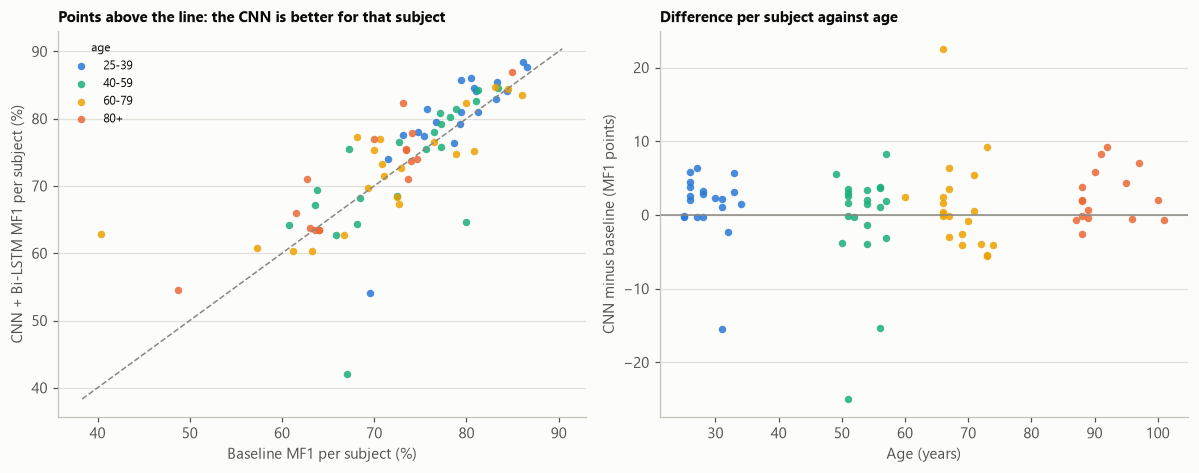

CNN - baseline over 78 subjects: +1.06 points (95% bootstrap CI -0.26 to +2.29), CNN better for 48 subjects, Wilcoxon p = 0.0052; typical seed-to-seed spread of a subject's MF1: 1.8 points


In [7]:
subj = subject_all[tested]
mf1_base = sd.per_subject_mf1(base_pred[tested], y_true, subj)
mf1_seed = pd.concat([sd.per_subject_mf1(runs[s]["probs"][tested].argmax(1), y_true, subj) for s in SEEDS], axis=1)
flag_subject = rec_table.groupby("subject")["flag_emg"].any()
per_subject = pd.DataFrame({"age": pd.Series(age_of), "flag_emg": flag_subject,
                            "baseline": mf1_base, "cnn": mf1_seed.mean(axis=1)}).loc[mf1_base.index]
per_subject["age group"] = pd.cut(per_subject["age"], AGE_BINS, labels=AGE_LABELS)
per_subject["diff"] = per_subject["cnn"] - per_subject["baseline"]

overall = sd.paired(per_subject["cnn"], per_subject["baseline"])
seed_spread = 100 * mf1_seed.std(axis=1).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for grp, d in per_subject.groupby("age group", observed=True):
    ax.scatter(100 * d["baseline"], 100 * d["cnn"], s=24, color=AGE_COLORS[grp], label=grp, alpha=0.85, linewidths=0)
lo, hi = 100 * per_subject[["baseline", "cnn"]].min().min() - 2, 100 * per_subject[["baseline", "cnn"]].max().max() + 2
ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
ax.set_xlabel("Baseline MF1 per subject (%)")
ax.set_ylabel("CNN + Bi-LSTM MF1 per subject (%)")
ax.legend(title="age", frameon=False, fontsize=8, title_fontsize=8)
ax.set_title("Points above the line: the CNN is better for that subject", fontsize=10)
ax = axes[1]
ax.axhline(0, color=MUTED, lw=1)
for grp, d in per_subject.groupby("age group", observed=True):
    ax.scatter(d["age"], 100 * d["diff"], s=24, color=AGE_COLORS[grp], alpha=0.85, linewidths=0)
ax.set_xlabel("Age (years)")
ax.set_ylabel("CNN minus baseline (MF1 points)")
ax.set_title("Difference per subject against age", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_cnn_sc78_per_subject.png")
plt.show()
print(f"CNN - baseline over {overall['subjects']} subjects: {overall['mean diff']:+.2f} points "
      f"(95% bootstrap CI {overall['CI low']:+.2f} to {overall['CI high']:+.2f}), CNN better for "
      f"{overall['better']} subjects, Wilcoxon p = {overall['p']:.4f}; "
      f"typical seed-to-seed spread of a subject's MF1: {seed_spread:.1f} points")

**Output.**
- Rerata selisih +1,06 poin, dengan interval kepercayaan 95% [−0,26; +2,29]. Interval dihitung dengan *bootstrap*, yaitu mengambil ulang subjek secara acak ribuan kali.
- Median selisih +1,6 poin. Model lebih baik pada 48 dari 78 subjek.
- Uji Wilcoxon, yang membandingkan peringkat selisih dan bukan besarnya, menghasilkan p = 0,005.
- Pada grafik kiri, sebagian besar titik berada sedikit di atas garis diagonal. Tiga titik jatuh jauh di bawahnya: subjek 36 (−25,0), 17 (−15,4), dan 25 (−15,3).

**Kesimpulan.**
- Kedua uji tidak bertentangan; keduanya menjawab pertanyaan berbeda. Wilcoxon bertanya apakah subjek pada umumnya lebih baik, dan jawabannya ya. Interval *bootstrap* bertanya tentang rerata, dan rerata itu ditarik ke bawah oleh tiga kegagalan besar.
- Jadi model ini lebih baik untuk subjek tipikal, tetapi belum dapat diandalkan: pada sebagian kecil orang hasilnya jauh lebih buruk daripada *baseline*.
- Ketiga kegagalan muncul pada ketiga *seed*, jadi penyebabnya bukan keacakan. Polanya:
  - tidur dalam (N3) dibaca sebagai tidur ringan (N2) pada subjek 25 dan 36;
  - REM sama sekali tidak dikenali pada subjek 36;
  - terjaga (Wake) dibaca sebagai REM atau N1 pada subjek 17.
- Penyebab pastinya belum diselidiki.

### G2. Jenis kesalahan per tahap

**Tujuan.** Melihat tahap mana yang lebih sering dikenali dan mana yang lebih sering terlewat oleh masing-masing model.

**Input.** Matriks kebingungan kedua model, dinormalkan per baris. Setiap baris menunjukkan ke mana *epoch* dari satu tahap sebenarnya diklasifikasikan.

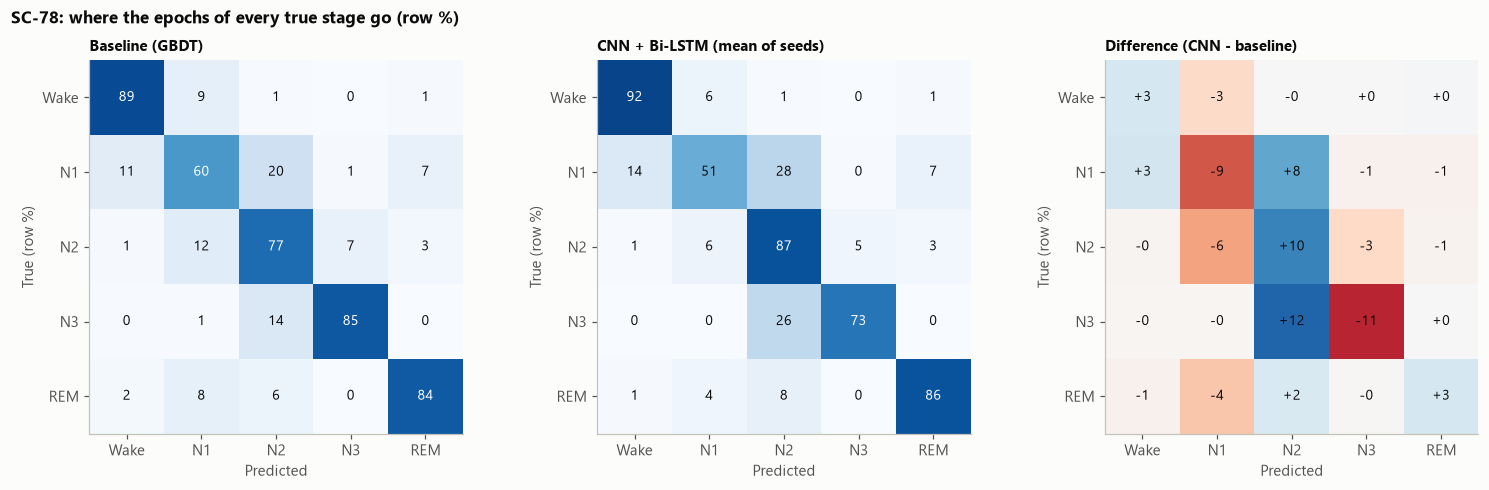

,Wake,N1,N2,N3,REM
Baseline (GBDT),89.3,60.0,76.9,84.6,83.8
CNN + Bi-LSTM (mean of seeds),92.0,50.7,86.8,73.2,86.4
Difference (CNN - baseline),2.7,-9.3,10.0,-11.4,2.6


In [8]:
def row_normalised(y, p):
    cm = confusion_matrix(y, p, labels=range(5)).astype(float)
    return 100 * cm / cm.sum(axis=1, keepdims=True)


matrices = {"Baseline (GBDT)": row_normalised(y_true, base_pred[tested]),
            "CNN + Bi-LSTM (mean of seeds)": np.mean([row_normalised(y_true, runs[s]["probs"][tested].argmax(1))
                                                      for s in SEEDS], axis=0)}
matrices["Difference (CNN - baseline)"] = matrices["CNN + Bi-LSTM (mean of seeds)"] - matrices["Baseline (GBDT)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (title, cm) in zip(axes, matrices.items()):
    diff = title.startswith("Difference")
    ax.imshow(cm, cmap="RdBu" if diff else "Blues", vmin=-15 if diff else 0, vmax=15 if diff else 100)
    for r in range(5):
        for c in range(5):
            ax.text(c, r, f"{cm[r, c]:+.0f}" if diff else f"{cm[r, c]:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if (not diff and cm[r, c] > 60) else INK)
    ax.set_xticks(range(5), STAGES)
    ax.set_yticks(range(5), STAGES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True (row %)")
    ax.grid(False)
    ax.set_title(title, fontsize=10)
fig.suptitle("SC-78: where the epochs of every true stage go (row %)", x=0.02, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_cnn_sc78_confusion.png")
plt.show()
pd.DataFrame({title: np.diag(cm).round(1) for title, cm in matrices.items()}, index=STAGES).T

**Output.**
- Sensitivitas CNN + Bi-LSTM dikurangi *baseline*: Wake +2,7; N1 −9,3; N2 +10,0; N3 −11,4; REM +2,6.
- CNN + Bi-LSTM membaca 26% *epoch* N3 sebagai N2, sedangkan *baseline* 14%.

**Kesimpulan.**
- Selisih N1 dan N3 terutama berasal dari cara kedua model dilatih, bukan dari arsitekturnya.
- *Baseline* dilatih dengan bobot kelas seimbang: kesalahan pada tahap yang jarang dihukum lebih berat. Akibatnya *baseline* cenderung lebih sering menebak tahap itu: N1 ditebak pada 14,9% *epoch* padahal porsi sebenarnya 11,0%, dan N3 pada 8,5% padahal porsinya 6,7%.
- CNN + Bi-LSTM dilatih tanpa bobot kelas, dan porsi tebakannya hampir sama dengan porsi sebenarnya (N1 10,2%, N3 6,6%). Model ini lebih jarang menangkap N1 dan N3, tetapi tebakannya lebih sering benar: *precision* N1 54,8 vs 44,3 dan N3 74,2 vs 66,7.
- Akibatnya F1-N1 tetap naik dan F1-N3 hanya turun 0,9. Efek bobot kelas pada model *deep learning* diuji langsung di notebook 06.

### G3. Kelompok usia

**Tujuan.** Memeriksa apakah keunggulan model berubah dengan usia subjek.

**Input.** Selisih MF1 per subjek, dikelompokkan menurut usia.

In [9]:
rows = {}
for grp, d in per_subject.groupby("age group", observed=True):
    t = sd.paired(d["cnn"], d["baseline"])
    rows[grp] = {"subjects": len(d), "baseline MF1": 100 * d["baseline"].mean(), "CNN MF1": 100 * d["cnn"].mean(),
                 "difference": t["mean diff"], "CI low": t["CI low"], "CI high": t["CI high"],
                 "CNN better": t["better"], "Wilcoxon p": t["p"]}
age_table = pd.DataFrame(rows).T
print(f"correlation of age with per-subject MF1: baseline {per_subject['age'].corr(per_subject['baseline']):.2f}, "
      f"CNN {per_subject['age'].corr(per_subject['cnn']):.2f}; "
      f"age with the CNN gain: {per_subject['age'].corr(per_subject['diff']):.2f}")
age_table.astype(float).round(2)

correlation of age with per-subject MF1: baseline -0.42, CNN -0.36; age with the CNN gain: 0.07


,subjects,baseline MF1,CNN MF1,difference,CI low,CI high,CNN better,Wilcoxon p
25-39,20.0,79.03,80.43,1.40,-0.73,3.05,14.0,0.01
40-59,21.0,73.17,72.65,-0.51,-3.83,2.14,13.0,0.41
60-79,21.0,71.25,72.43,1.18,-1.17,4.03,11.0,0.84
80+,16.0,68.67,71.19,2.52,0.89,4.28,10.0,0.02


**Output.**

| Usia | Subjek | *Baseline* | CNN + Bi-LSTM | Selisih [95% CI] | Subjek yang lebih baik | p (dikoreksi Holm) |
|---|---|---|---|---|---|---|
| 25–39 | 20 | 79,0 | 80,4 | +1,4 [−0,7; +3,0] | 14 | 0,048 |
| 40–59 | 21 | 73,2 | 72,7 | −0,5 [−3,8; +2,1] | 13 | 0,82 |
| 60–79 | 21 | 71,2 | 72,4 | +1,2 [−1,2; +4,0] | 11 | 0,84 |
| 80+ | 16 | 68,7 | 71,2 | +2,5 [+0,9; +4,3] | 10 | 0,075 |

- Koreksi Holm menyesuaikan nilai p karena ada empat uji sekaligus; tabel di keluaran notebook memuat nilai p sebelum dikoreksi.
- Korelasi usia dengan MF1 per subjek: −0,42 untuk *baseline* dan −0,36 untuk CNN + Bi-LSTM.
- Korelasi usia dengan selisih antar-model: 0,07.

**Kesimpulan.**
- Kedua model sama-sama memburuk pada subjek yang lebih tua, dengan laju yang mirip. Keunggulan CNN + Bi-LSTM tidak membesar atau mengecil seiring usia.
- Kelompok 40–59 tahun bernilai negatif karena memuat dua dari tiga kegagalan besar (subjek 25 dan 36).
- Hasil ini eksploratif: tiap kelompok hanya berisi 16–21 subjek, dan kelompok termuda adalah subjek yang dipakai selama pengembangan model.

### G4. Rekaman dengan EMG bermasalah

**Tujuan.** EMG (aktivitas otot dagu) membantu mengenali REM. Bagian ini memeriksa apakah 17 rekaman dengan EMG bermasalah lebih merugikan CNN + Bi-LSTM daripada *baseline*.

**Input.** Tanda EMG bermasalah dari notebook 02. Karena 11 dari 17 rekaman itu berasal dari subjek tua, perbandingan yang adil dilakukan di antara subjek berusia 60 tahun ke atas.

In [10]:
flag_rec = np.concatenate([[r["flag_emg"]] * len(r["labels"]) for r in records])[tested]
cnn_pred_seeds = [runs[s]["probs"][tested].argmax(1) for s in SEEDS]
rows = {}
for name, keep in [("all recordings", np.ones_like(flag_rec)), ("without EMG-flagged recordings", ~flag_rec),
                   ("EMG-flagged recordings only", flag_rec)]:
    rows[name] = {"recordings": len({r for r, k in zip(rec_all[tested], keep) if k}), "epochs": int(keep.sum()),
                  "baseline MF1": 100 * sd.summarise(y_true[keep], base_pred[tested][keep])["MF1"],
                  "CNN MF1": 100 * np.mean([sd.summarise(y_true[keep], p[keep])["MF1"] for p in cnn_pred_seeds]),
                  "CNN F1-REM": 100 * np.mean([sd.summarise(y_true[keep], p[keep])["F1_REM"] for p in cnn_pred_seeds]),
                  "baseline F1-REM": 100 * sd.summarise(y_true[keep], base_pred[tested][keep])["F1_REM"]}
emg_table = pd.DataFrame(rows).T

# Age is the confounder (most flagged recordings belong to subjects of 80+); compare within subjects aged 60 or more
old = per_subject[per_subject["age"] >= 60]
within_old = old.groupby("flag_emg")[["baseline", "cnn", "diff"]].mean().mul(100).round(1)
within_old.insert(0, "subjects", old.groupby("flag_emg").size())
print("subjects aged 60+, per-subject MF1 by EMG flag:")
print(within_old.to_string())
emg_table.astype(float).round(1)

subjects aged 60+, per-subject MF1 by EMG flag:
          subjects  baseline   cnn  diff
flag_emg                                
False           26      71.6  72.7   1.1
True            11      66.7  70.0   3.3


,recordings,epochs,baseline MF1,CNN MF1,CNN F1-REM,baseline F1-REM
all recordings,153.0,195469.0,76.5,78.0,85.6,83.5
without EMG-flagged recordings,136.0,170744.0,77.0,78.3,86.8,84.9
EMG-flagged recordings only,17.0,24725.0,72.2,75.3,75.0,71.6


**Output.**
- Pada 17 rekaman bertanda, MF1 *baseline* 72,2 vs CNN + Bi-LSTM 75,3, dan F1-REM 71,6 vs 75,0.
- Pada subjek berusia 60 tahun ke atas:

| | MF1 *baseline* | MF1 CNN + Bi-LSTM | Selisih |
|---|---|---|---|
| Dengan rekaman bertanda (11 subjek) | 66,7 | 70,0 | +3,3 |
| Tanpa tanda (26 subjek) | 71,6 | 72,7 | +1,1 |

**Kesimpulan.** EMG yang buruk menurunkan kedua model, tetapi CNN + Bi-LSTM tidak lebih terdampak; selisihnya malah lebih besar pada rekaman bertanda. Jadi rekaman ini tidak perlu dibuang dari evaluasi. Kesimpulan ini lemah karena hanya didukung 11 subjek.

### G5. Efek menambah data latih pada 20 subjek muda

**Tujuan.** Penurunan MF1 dari 80,1 (notebook 04) ke 78,0 (notebook ini) bisa berarti model memburuk, atau data ujinya yang lebih sulit. Untuk membedakannya, 20 subjek muda yang sama dibandingkan di bawah dua kondisi.

**Input.** Prediksi notebook 04, yang dilatih pada 17 subjek muda, dan prediksi notebook ini, yang dilatih pada sekitar 63 subjek dari semua usia. Subjek ujinya sama.

In [11]:
# Same 20 subjects (SC-20), two training-set sizes: notebook 04 (LOSO, 17 training subjects, all aged 25-34)
# and this notebook (10 folds, about 63 training subjects of all ages). Same model, loss and seeds.
m20 = subject_all < 20
sc20 = [np.load(SC20_RUNS / f"ce_seed{s}.npz") for s in SEEDS]
assert all('"loss": "ce"' in str(z["config"]) for z in sc20) and all(len(z["probs"]) == m20.sum() for z in sc20)
with np.load(ROOT / "data" / "processed" / "cnn_sc20_predictions.npz") as z04:      # epoch order of notebook 04
    assert np.array_equal(z04["rec"], rec_all[m20]) and np.array_equal(z04["epoch_idx"], epoch_idx_all[m20])
t20 = m20 & tested
y20, s20 = labels_all[t20], subject_all[t20]
mf1_04 = pd.concat([sd.per_subject_mf1(z["probs"][t20[m20]].argmax(1), y20, s20) for z in sc20], axis=1).mean(axis=1)
mf1_05 = pd.concat([sd.per_subject_mf1(runs[s]["probs"][t20].argmax(1), y20, s20) for s in SEEDS], axis=1).mean(axis=1)
scaling = sd.paired(mf1_05, mf1_04)
n_train_05 = np.mean([78 - len(f["test"]) - len(f["val"]) for f in FOLDS])
pooled = {"notebook 04 (17 training subjects)": np.mean([sd.summarise(y20, z["probs"][t20[m20]].argmax(1))["MF1"] for z in sc20]),
          f"notebook 05 (~{n_train_05:.0f} training subjects)": np.mean([sd.summarise(y20, runs[s]["probs"][t20].argmax(1))["MF1"] for s in SEEDS])}
print({k: f"{100 * v:.1f}" for k, v in pooled.items()})
print(f"per subject, more training subjects minus fewer: {scaling['mean diff']:+.2f} points "
      f"(95% CI {scaling['CI low']:+.2f} to {scaling['CI high']:+.2f}), better for {scaling['better']} of "
      f"{scaling['subjects']}, Wilcoxon p = {scaling['p']:.4f}")

{'notebook 04 (17 training subjects)': '80.1', 'notebook 05 (~63 training subjects)': '80.8'}
per subject, more training subjects minus fewer: +1.15 points (95% CI -0.42 to +2.46), better for 14 of 20, Wilcoxon p = 0.0296


**Output.**
- MF1 gabungan 80,1 (notebook 04) vs 80,8 (notebook ini).
- Per subjek +1,15 poin [−0,42; +2,46]; lebih baik pada 14 dari 20 subjek; Wilcoxon p = 0,030.
- Subjek 17 turun dari 63,8 ke 54,1.

**Kesimpulan.**
- Penurunan MF1 di notebook ini berasal dari data uji yang lebih sulit, bukan dari model yang memburuk. Pada subjek yang sama, menambah subjek latih termasuk subjek tua justru sedikit memperbaiki hasil.
- Bagian ini tidak bisa memisahkan efek jumlah data dari keragaman data, karena keduanya berubah bersamaan.

### G6. Kurva pelatihan

**Tujuan.** Melihat kapan model mencapai performa terbaiknya, dan seberapa stabil skor validasi yang dipakai untuk menghentikan pelatihan.

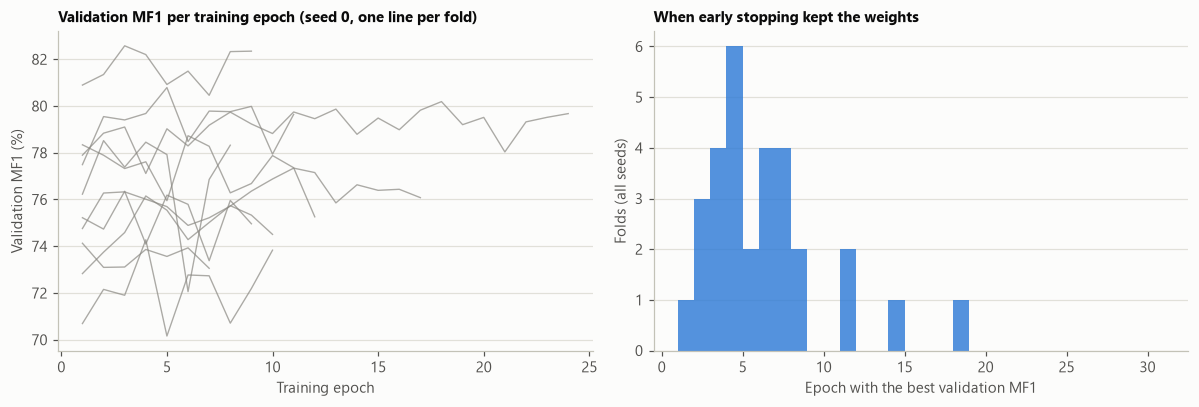

best epoch: median 5, range 1-18 of max 30; minutes per run: seed 0 54, seed 1 59, seed 2 55


In [12]:
stops = np.concatenate([r["best_epoch"] for r in runs.values()])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for fold, hist in runs[SEEDS[0]]["history"].items():
    h = pd.DataFrame(hist)
    axes[0].plot(h["epoch"], 100 * h["val_mf1"], color=MUTED, lw=0.9, alpha=0.7)
axes[0].set_xlabel("Training epoch")
axes[0].set_ylabel("Validation MF1 (%)")
axes[0].set_title(f"Validation MF1 per training epoch (seed {SEEDS[0]}, one line per fold)", fontsize=10)
axes[1].hist(stops, bins=range(1, CONFIG["max_epochs"] + 2), color=STAGE_COLORS["Wake"], alpha=0.8)
axes[1].set_xlabel("Epoch with the best validation MF1")
axes[1].set_ylabel("Folds (all seeds)")
axes[1].set_title("When early stopping kept the weights", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_cnn_sc78_training.png")
plt.show()
print(f"best epoch: median {np.median(stops):.0f}, range {stops.min()}-{stops.max()} of max {CONFIG['max_epochs']}; "
      "minutes per run: " + ", ".join(f"seed {s} {r['minutes']:.0f}" for s, r in runs.items()))

**Output.**
- Putaran latih terbaik: median 5, rentang 1–18 dari maksimum 30.
- MF1 validasi sering naik-turun 2 poin atau lebih antar-putaran, kadang sampai sekitar 6 poin.

**Kesimpulan.**
- Model belajar cepat; sebagian besar *fold* mencapai puncaknya dalam beberapa putaran.
- Skor validasi yang naik-turun menunjukkan 7–8 subjek validasi memberi sinyal yang berisik, sehingga pemilihan putaran terbaik sebagian ditentukan kebetulan. Ini salah satu sumber variasi antar-*fold*.
- Perbaikan yang bisa dicoba nanti: merata-ratakan bobot beberapa putaran terakhir, atau menghaluskan skor validasi. Keduanya tidak dikerjakan di sini agar pengaturan tetap sama dengan notebook 04.

## H. Penyimpanan

**Tujuan.** Menyimpan tabel, gambar, dan probabilitas prediksi untuk laporan dan untuk uji pada data eksternal (Sleep Telemetry, notebook berikutnya).

In [13]:
per_run.to_csv(TAB_DIR / "05_cnn_sc78_runs.csv", index=False)
table.to_csv(TAB_DIR / "05_cnn_sc78_metrics.csv")
per_subject.to_csv(TAB_DIR / "05_cnn_sc78_per_subject.csv")
age_table.to_csv(TAB_DIR / "05_cnn_sc78_age_groups.csv")
emg_table.to_csv(TAB_DIR / "05_cnn_sc78_emg.csv")
pd.DataFrame({"CNN vs baseline (78 subjects)": overall,
              "SC-20 subjects: ~63 vs 17 training subjects": scaling}).T.to_csv(TAB_DIR / "05_cnn_sc78_paired_tests.csv")
np.savez(PREDICTIONS, rec=rec_all, epoch_idx=epoch_idx_all, y=labels_all,
         probs=np.mean([runs[s]["probs"] for s in SEEDS], axis=0))
print("tables:", sorted(p.name for p in TAB_DIR.glob("05_cnn_sc78_*.csv")))
print(f"SC-78: CNN + Bi-LSTM MF1 {100 * per_run['MF1'].mean():.1f} ± {100 * per_run['MF1'].std():.1f} "
      f"vs baseline {100 * base_res['MF1']:.1f}; per subject {overall['mean diff']:+.2f} points, p = {overall['p']:.4f}")

tables: ['05_cnn_sc78_age_groups.csv', '05_cnn_sc78_emg.csv', '05_cnn_sc78_metrics.csv', '05_cnn_sc78_paired_tests.csv', '05_cnn_sc78_per_subject.csv', '05_cnn_sc78_runs.csv']
SC-78: CNN + Bi-LSTM MF1 78.0 ± 0.6 vs baseline 76.5; per subject +1.06 points, p = 0.0052


**Output.** Enam tabel, tiga gambar, dan probabilitas rerata tiga *seed* untuk setiap *epoch*.

## Kesimpulan

1. **Keseluruhan.** Pada 78 subjek, CNN + Bi-LSTM lebih baik daripada *baseline*: Macro-F1 78,0 vs 76,5 dan κ 0,774 vs 0,739.
2. **Per subjek.** Untuk subjek tipikal keunggulannya nyata (48 dari 78 subjek, p = 0,005). Namun rerata per subjek belum terbukti di atas nol karena model gagal parah pada tiga subjek.
3. **N1 dan N3.** Perbedaan pengenalan kedua tahap ini terutama mencerminkan bobot kelas pada *baseline*, bukan kelemahan arsitektur.
4. **Usia dan EMG.** Keunggulan model tidak bergantung pada usia dan tetap ada pada rekaman dengan EMG bermasalah.
5. **Penurunan dari notebook 04.** MF1 yang lebih rendah daripada notebook 04 berasal dari data uji yang lebih sulit, bukan dari model yang memburuk.

**Keterbatasan.**
- Penyebab tiga kegagalan besar belum diketahui.
- Kelompok usia termuda bukan data yang sepenuhnya baru, karena dipakai selama pengembangan model. Data yang benar-benar baru baru diuji di Sleep Telemetry.

**Catatan teknis.**
- **Kode.** Model, pelatihan, dan evaluasi ada di `src/sleep_dl.py`, dan kesetaraannya dengan notebook 04 diuji oleh `tests/test_sleep_dl.py`.
- **Keputusan desain.** Alasan membekukan pengaturan dicatat sebagai K7 di `docs/catatan/KEPUTUSAN_DESAIN.md`. Bobot kelas *baseline* dicatat sebagai K5.
- **Run yang terputus.** Pelatihan *seed* 0 dan 1 sempat berhenti karena RAM laptop penuh. Pelatihan dilanjutkan dari *fold* terakhir yang tersimpan di `data/processed/cnn_sc78_runs/`, sehingga hasilnya sama dengan *run* tanpa gangguan.
- **Berkas hasil.**
  - Tabel: `results/tables/05_cnn_sc78_*.csv`.
  - Gambar: `results/figures/05_cnn_sc78_*.png`.
  - Probabilitas prediksi: `data/processed/cnn_sc78_predictions.npz`.
- **Penjelasan per sel** untuk presentasi ada di `docs/belajar/05_cnn_bilstm_sc78_penjelasan.md`.